# Exploratory analysis of the 20 companies

Before building the dashboard Insights view, I explored the Gold tables to understand what the data can support: what is in it, where the gaps sit, how the distributions look, and what patterns emerge across companies and sectors over the five-year window.

This notebook investigates four questions:
1. **Growth:** Which companies grew fastest, and is that growth steady, cyclical, or driven by a single year?
2. **Profitability:** How do net margins and free cash flow margins compare across different business models?
3. **Cash conversion:** How much of reported net income turns into actual free cash flow, and what explains the gaps?
4. **Capital spending:** How much are the cloud companies spending on equipment, and how does it affect their free cash?

It runs against the committed demo database (`demo/sec_edgar_demo.duckdb`), a dated snapshot of the 20-company cohort with filings through October 15, 2026. The live dataset covers the S&P 500 and refreshes on weeknights; set `SEC_EDGAR_DUCKDB_PATH` to a newer snapshot to run the same queries on it.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists()
)
DATABASE = ROOT / os.environ.get("SEC_EDGAR_DUCKDB_PATH", "demo/sec_edgar_demo.duckdb")
connection = duckdb.connect(str(DATABASE), read_only=True)


def sql(query: str) -> pd.DataFrame:
    """Run a query against the Gold tables and return a DataFrame."""
    return connection.sql(query).df()


BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TEXT, MUTED, GRID = "#14243e", "#5b6474", "#e6e9ee"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 9,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": TEXT,
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
    }
)
pd.set_option("display.float_format", "{:,.3f}".format)
print("Reading", DATABASE.name)

Reading sec_edgar_demo.duckdb


## 1. Data Hand-off & Cohort Integrity

We verify the tables delivered by the Gold layer and examine the cohort profile. Values arrive in pandas as floats for exploratory convenience; Gold itself stores exact decimals, which matters for fact-level tracing back to source XBRL instances.

In [2]:
tables = sql(
    "select table_name from duckdb_tables() where schema_name = 'gold' order by 1"
)["table_name"]
pd.DataFrame(
    {
        "rows": [
            connection.sql(f"select count(*) from gold.{name}").fetchone()[0]
            for name in tables
        ]
    },
    index=tables,
)

,rows
table_name,
company_insights,20
company_metric_coverage,160
dim_companies,20
dim_filings,400
fct_company_financials,500
fct_financial_metrics,4310
metric_quality_issues,557


In [3]:
companies = sql("""
    select coalesce(primary_ticker, company_name) as company, company_name, sector,
           fiscal_year_end, filing_count, first_fiscal_year, last_fiscal_year
    from gold.dim_companies
    order by company
""")
companies["fiscal_year_end"] = pd.to_datetime(
    "2001" + companies["fiscal_year_end"], format="%Y%m%d"
).dt.strftime("%b %d")
companies

,company,company_name,sector,fiscal_year_end,filing_count,first_fiscal_year,last_fiscal_year
0,AAPL,Apple Inc.,Technology,Sep 26,20,2021,2025
1,ABBV,AbbVie Inc.,Life Sciences,Dec 31,20,2021,2025
2,AMD,ADVANCED MICRO DEVICES INC,Manufacturing,Dec 26,20,2021,2025
3,AMZN,AMAZON COM INC,Trade & Services,Dec 31,20,2021,2025
4,AVGO,Broadcom Inc.,Manufacturing,Nov 01,20,2021,2025
5,BRK-B,BERKSHIRE HATHAWAY INC,Finance,Dec 31,20,2021,2025
6,EXXON MOBIL CORP,EXXON MOBIL CORP,Energy & Transportation,Dec 31,20,2021,2025
7,GOOGL,Alphabet Inc.,Technology,Dec 31,20,2021,2025
8,JNJ,JOHNSON & JOHNSON,Life Sciences,Jan 03,20,2021,2025
9,JPM,JPMORGAN CHASE & CO,Finance,Dec 31,20,2021,2025


In [4]:
sector_cohort = sql("""
    select coalesce(sector, 'Other') as sector,
           count(*) as companies,
           string_agg(coalesce(primary_ticker, company_name), ', ' order by coalesce(primary_ticker, company_name)) as cohort_members
    from gold.dim_companies
    group by sector
    order by companies desc
""")
sector_cohort

,sector,companies,cohort_members
0,Manufacturing,5,"AMD, AVGO, MU, NVDA, TSLA"
1,Technology,5,"AAPL, GOOGL, META, MSFT, PLTR"
2,Trade & Services,4,"AMZN, MA, V, WMT"
3,Life Sciences,3,"ABBV, JNJ, LLY"
4,Finance,2,"BRK-B, JPM"
5,Energy & Transportation,1,EXXON MOBIL CORP


Eleven companies end their fiscal year on December 31, and nine do not. NVIDIA's and Walmart's fiscal years end around January 31, so their "FY2026" is mostly calendar 2025. Microsoft ends in June, Micron in early September, and Apple in late September. Comparing "FY2025" across companies therefore compares different calendar months, so our analysis uses each company's own latest fiscal year and never blends unaligned quarters across companies.

In [5]:
financials = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company, f.*
    from gold.fct_company_financials as f
    join gold.dim_companies as c using (cik)
""")
annual = financials[financials["fiscal_period"] == "FY"].copy()
print(financials.shape, "company-period rows;", annual.shape[0], "annual rows")
financials.groupby("fiscal_period").size().rename("rows").to_frame().T

(500, 23) company-period rows; 100 annual rows


fiscal_period,FY,Q1,Q2,Q3,Q4
rows,100,100,100,100,100


Each company has exactly five fiscal years with an annual row and four quarters, 25 rows in all. The table grain is clean: no duplicates, no missing periods.

## 2. Metric Coverage & Structural Missingness

Gold leaves a value empty when the filing's evidence doesn't support one, and records why in `metric_quality_issues`. A gap means "withheld by design", never zero. `company_metric_coverage` audits how many of the 25 expected periods have a value (20 for diluted EPS, which Gold never derives for Q4).

In [6]:
coverage = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company, m.*
    from gold.company_metric_coverage as m
    join gold.dim_companies as c using (cik)
""")
present, expected = (
    coverage["periods_present"].sum(),
    coverage["periods_expected"].sum(),
)
print(
    f"{present:,} of {expected:,} company-metric periods have a value ({present / expected:.1%})"
)
coverage.groupby("metric_code")[["periods_present", "periods_expected"]].sum().assign(
    coverage=lambda t: t["periods_present"] / t["periods_expected"]
).sort_values("coverage")

3,611 of 3,900 company-metric periods have a value (92.6%)


,periods_present,periods_expected,coverage
metric_code,,,
total_liabilities,367,500,0.734
cash_and_equivalents,440,500,0.880
diluted_eps,359,400,0.897
capital_expenditures,465,500,0.930
revenue,480,500,0.960
net_income,500,500,1.000
operating_cash_flow,500,500,1.000
total_assets,500,500,1.000


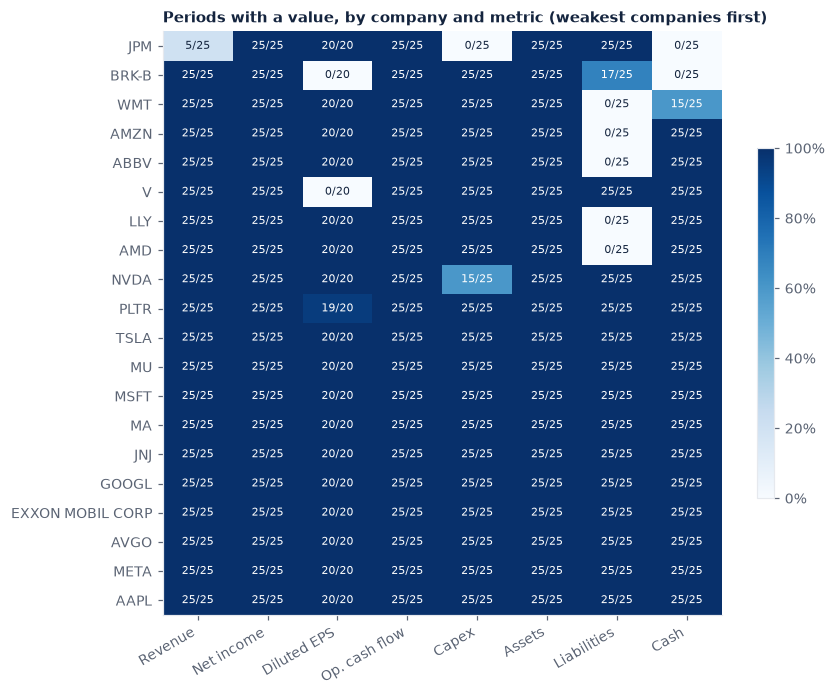

In [7]:
metrics = [
    "revenue",
    "net_income",
    "diluted_eps",
    "operating_cash_flow",
    "capital_expenditures",
    "total_assets",
    "total_liabilities",
    "cash_and_equivalents",
]
labels = [
    "Revenue",
    "Net income",
    "Diluted EPS",
    "Op. cash flow",
    "Capex",
    "Assets",
    "Liabilities",
    "Cash",
]
grid = coverage.pivot(index="company", columns="metric_code", values="coverage")[
    metrics
]
grid = grid.loc[grid.mean(axis=1).sort_values().index]
counts = coverage.assign(
    cell=lambda t: (
        t["periods_present"].astype(str) + "/" + t["periods_expected"].astype(str)
    )
)
counts = counts.pivot(index="company", columns="metric_code", values="cell").loc[
    grid.index, metrics
]

fig, ax = plt.subplots(figsize=(8, 6.4))
image = ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(grid.index)), grid.index)
ax.grid(False)
for (row, column), value in pd.DataFrame(grid.values).stack().items():
    ax.text(
        column,
        row,
        counts.iat[row, column],
        ha="center",
        va="center",
        fontsize=7,
        color="white" if value >= 0.5 else TEXT,
    )
ax.set_title("Periods with a value, by company and metric (weakest companies first)")
fig.colorbar(image, ax=ax, shrink=0.6, format="{x:.0%}")
plt.tight_layout()

In [8]:
reasons = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company, i.metric_code,
           string_agg(i.issue_code || ' × ' || i.issues, ', ' order by i.issues desc) as recorded_issues
    from (
        select cik, metric_code, issue_code, count(*) as issues
        from gold.metric_quality_issues
        group by cik, metric_code, issue_code
    ) as i
    join gold.dim_companies as c using (cik)
    group by company, i.metric_code
    order by company, i.metric_code
""")
reasons.head(10)

,company,metric_code,recorded_issues
0,ABBV,diluted_eps,UNSUPPORTED_DURATION × 5
1,ABBV,net_income,"LOWER_PRIORITY_CONCEPT_DIFFERS × 30, UNSUPPORT..."
2,ABBV,revenue,UNSUPPORTED_DURATION × 5
3,ABBV,total_liabilities,NO_ELIGIBLE_METRIC × 20
4,AMD,total_liabilities,NO_ELIGIBLE_METRIC × 20
5,AMZN,capital_expenditures,UNSUPPORTED_DURATION × 15
6,AMZN,net_income,UNSUPPORTED_DURATION × 15
7,AMZN,operating_cash_flow,UNSUPPORTED_DURATION × 15
8,AMZN,total_liabilities,NO_ELIGIBLE_METRIC × 20
9,BRK-B,cash_and_equivalents,NO_ELIGIBLE_METRIC × 20


The gaps are concentrated, and each one traces back to how the company tags its filings:

- **Total liabilities is missing entirely for five companies:** AbbVie, AMD, Amazon, Eli Lilly, and Walmart. None tags a consolidated `us-gaap:Liabilities` fact in their filings; their balance sheets list individual liabilities and proceed directly to equity. Gold correctly refuses to synthesize an unaudited total, so the gap remains.
- **JPMorgan** reports no capital expenditures or cash-and-equivalents figures in standard non-financial formats; banks present their cash flow and balance sheet differently.
- **Berkshire and Visa** report EPS per share class, so consolidated diluted EPS is absent.
- **Walmart cash** is missing at fiscal year-end because its own year-end cash facts contradict each other in the 10-K (`METRIC_VALUE_CONFLICT`), so Gold withholds the value instead of picking one.

Revenue, net income, and operating cash flow are nearly complete; the balance sheet is not. A ratio like liabilities over assets would silently drop a quarter of the cohort. That is why this analysis uses income and cash-flow measures instead.

## 3. Revenue Growth Durability & Sector Trajectories

We analyze top-line expansion across the cohort. Because company sizes span two orders of magnitude ($4.5B Palantir vs. $717B Amazon), direct dollar comparisons are misleading; we analyze Compound Annual Growth Rates (CAGR) and indexed growth trajectories.

In [9]:
growth_ranking = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company,
           coalesce(c.sector, 'Other') as sector,
           'FY' || i.first_fiscal_year || '–FY' || i.latest_fiscal_year as years,
           round(i.first_revenue / 1e9, 1) as first_revenue_bn,
           round(i.latest_revenue / 1e9, 1) as latest_revenue_bn,
           round(i.revenue_cagr * 100, 1) as revenue_cagr_pct
    from gold.company_insights as i
    join gold.dim_companies as c using (cik)
    where i.revenue_cagr is not null
    order by i.revenue_cagr desc
""")
growth_ranking

,company,sector,years,first_revenue_bn,latest_revenue_bn,revenue_cagr_pct
0,NVDA,Manufacturing,FY2022–FY2026,26.900,215.900,68.300
1,MU,Manufacturing,FY2022–FY2026,30.800,133.200,44.300
2,PLTR,Technology,FY2021–FY2025,1.500,4.500,30.500
3,AVGO,Manufacturing,FY2021–FY2025,27.500,63.900,23.500
4,LLY,Life Sciences,FY2021–FY2025,28.300,65.200,23.200
5,AMD,Manufacturing,FY2021–FY2025,16.400,34.600,20.500
6,TSLA,Manufacturing,FY2021–FY2025,53.800,94.800,15.200
7,MA,Trade & Services,FY2021–FY2025,18.900,32.800,14.800
8,META,Technology,FY2021–FY2025,117.900,201.000,14.300
9,MSFT,Technology,FY2022–FY2026,198.300,331.800,13.700


In [10]:
sector_growth = sql("""
    select coalesce(c.sector, 'Other') as sector,
           count(*) as count,
           round(median(i.revenue_cagr) * 100, 1) as median_cagr_pct,
           round(min(i.revenue_cagr) * 100, 1) as min_cagr_pct,
           round(max(i.revenue_cagr) * 100, 1) as max_cagr_pct
    from gold.company_insights as i
    join gold.dim_companies as c using (cik)
    where i.revenue_cagr is not null
    group by sector
    order by median_cagr_pct desc
""")
sector_growth

,sector,count,median_cagr_pct,min_cagr_pct,max_cagr_pct
0,Manufacturing,5,23.500,15.200,68.300
1,Technology,5,13.700,3.300,30.500
2,Trade & Services,4,12.300,5.600,14.800
3,Finance,2,9.200,7.700,10.700
4,Energy & Transportation,1,3.900,3.900,3.900
5,Life Sciences,3,2.100,0.100,23.200


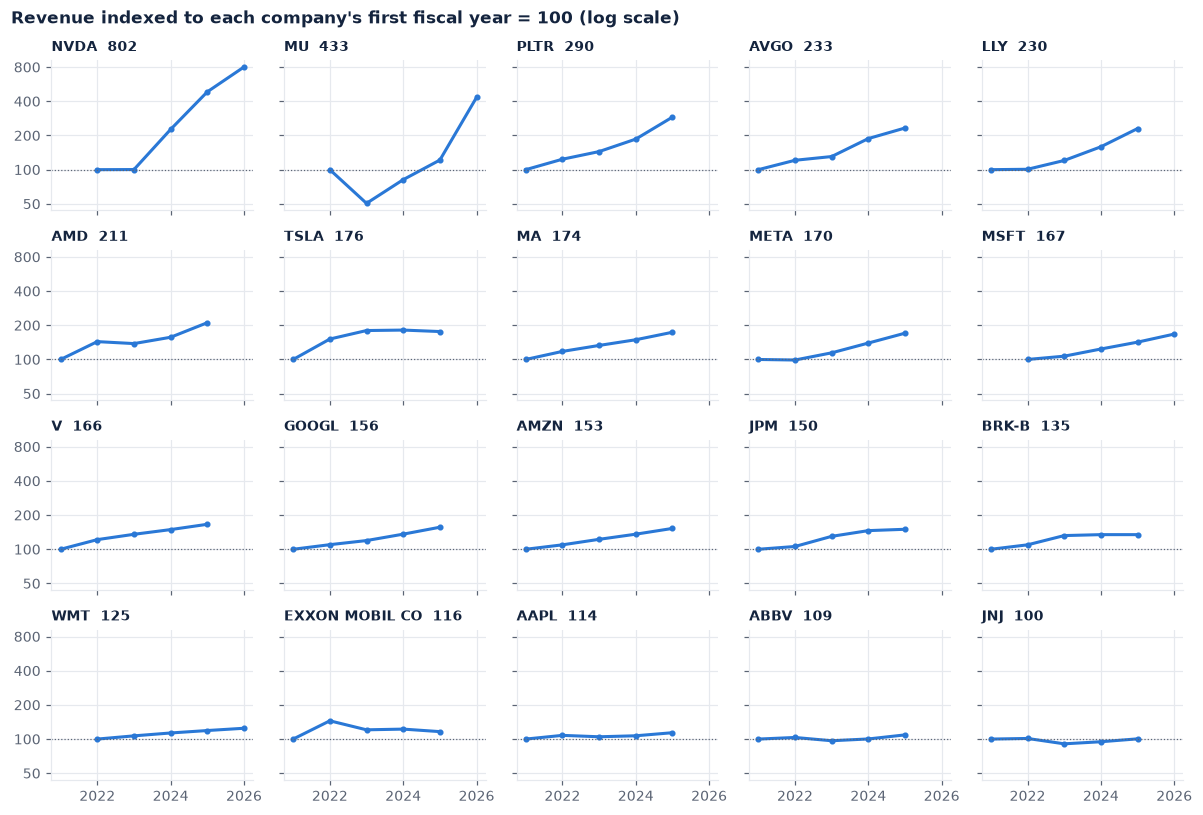

In [11]:
indexed = annual.pivot(index="fiscal_year", columns="company", values="revenue")
indexed = indexed.apply(lambda s: s / s.dropna().iloc[0] * 100)
order = indexed.apply(lambda s: s.dropna().iloc[-1]).sort_values(ascending=False).index

fig, axes = plt.subplots(4, 5, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, company in zip(axes.flat, order):
    series = indexed[company].dropna()
    ax.plot(
        series.index, series.values, color=BLUE, linewidth=2, marker="o", markersize=3
    )
    ax.axhline(100, color=MUTED, linewidth=0.8, linestyle=":")
    ax.set_title(f"{company[:14]}  {series.iloc[-1]:.0f}", fontsize=9)
    ax.set_yscale("log")
    ax.set_yticks([50, 100, 200, 400, 800], ["50", "100", "200", "400", "800"])
    ax.minorticks_off()
fig.suptitle(
    "Revenue indexed to each company's first fiscal year = 100 (log scale)",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=TEXT,
)
plt.tight_layout()

- **Secular AI growth:** NVIDIA grew eightfold (index 802), compounding at 68.3% a year from $26.9B to $215.9B.
- **Cyclical spike vs. trend:** Micron exhibits a 44.3% CAGR, but this is driven by an extreme memory price swing: revenue collapsed to $15.5B in FY2023 with a net loss, before rebounding 3.6× in FY2026 to $133.2B.
- **Mature compounders:** High-volume retailers and consumer businesses (Walmart at 5.6%, Apple at 3.3%, Exxon at 3.9%) demonstrate resilient, low-single-digit expansion on enormous revenue bases.

## 4. Sector Margin Profiles & Operating Leverage

We evaluate how different corporate operating models convert revenue into profit and free cash flow. We analyze Net Margin alongside Free Cash Flow Margin.

In [12]:
margin_profile = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company,
           coalesce(c.sector, 'Other') as sector,
           i.latest_fiscal_year as fiscal_year,
           round(i.latest_net_margin * 100, 1) as net_margin_pct,
           round(i.latest_free_cash_flow_margin * 100, 1) as fcf_margin_pct,
           round((i.latest_free_cash_flow_margin - i.latest_net_margin) * 100, 1) as margin_spread_pct
    from gold.company_insights as i
    join gold.dim_companies as c using (cik)
    order by i.latest_net_margin desc nulls last
""")
margin_profile

,company,sector,fiscal_year,net_margin_pct,fcf_margin_pct,margin_spread_pct
0,MU,Manufacturing,2026,63.800,44.300,-19.500
1,NVDA,Manufacturing,2026,55.600,44.800,-10.800
2,V,Trade & Services,2025,50.100,53.900,3.800
3,MA,Trade & Services,2025,45.600,52.300,6.700
4,MSFT,Technology,2026,40.300,20.200,-20.100
5,PLTR,Technology,2025,36.300,46.900,10.600
6,AVGO,Manufacturing,2025,36.200,42.100,5.900
7,GOOGL,Technology,2025,32.800,18.200,-14.600
8,LLY,Life Sciences,2025,31.700,13.800,-17.900
9,JPM,Finance,2025,31.300,NaN,NaN


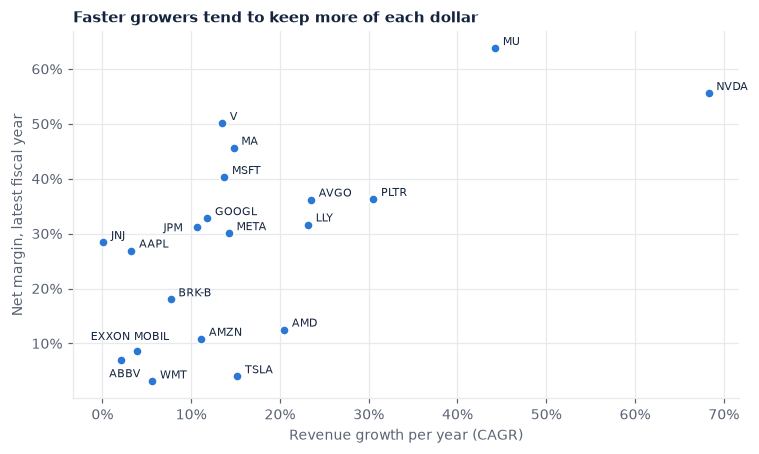

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.2))
points = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company,
           i.revenue_cagr,
           i.latest_net_margin
    from gold.company_insights as i
    join gold.dim_companies as c using (cik)
    where i.revenue_cagr is not null and i.latest_net_margin is not null
""")
ax.scatter(
    points["revenue_cagr"],
    points["latest_net_margin"],
    color=BLUE,
    s=36,
    edgecolor="white",
    zorder=3,
)
offsets = {"JPM": (-22, -3), "ABBV": (-8, -11), "EXXON MOBIL CORP": (-30, 7)}
for _, row in points.iterrows():
    ax.annotate(
        row["company"][:11],
        (row["revenue_cagr"], row["latest_net_margin"]),
        xytext=offsets.get(row["company"], (5, 2)),
        textcoords="offset points",
        fontsize=7.5,
        color=TEXT,
    )
ax.xaxis.set_major_formatter("{x:.0%}")
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_xlabel("Revenue growth per year (CAGR)")
ax.set_ylabel("Net margin, latest fiscal year")
ax.set_title("Faster growers tend to keep more of each dollar")
plt.tight_layout()

- **Asset-light payment rails:** Visa (50.1% net margin, 53.9% FCF margin) and Mastercard (45.6% net margin, 52.3% FCF margin) lead both measures. They convert more than 100% of profit into free cash because they require minimal capital reinvestment to scale.
- **Enterprise software & Cloud:** Microsoft maintains a 40.3% net margin, but heavy AI infrastructure spending halves its FCF margin to 20.2%.
- **High-volume retail:** Walmart operates on a 3.1% net margin and 2.1% FCF margin, illustrating high inventory turnover rather than pricing power.

## 5. Cash conversion

Net income is an accounting measure; free cash flow is cash. **Cash conversion** ($\text{Free Cash Flow} / \text{Net Income}$) shows how much of reported profit arrived as cash.

In [14]:
conversion_table = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company,
           round(i.latest_net_income / 1e9, 1) as net_income_bn,
           round(i.latest_free_cash_flow / 1e9, 1) as free_cash_flow_bn,
           round(i.cash_conversion * 100) as conversion_pct
    from gold.company_insights as i
    join gold.dim_companies as c using (cik)
    order by i.cash_conversion desc nulls last
""")
conversion_table

,company,net_income_bn,free_cash_flow_bn,conversion_pct
0,ABBV,4.200,17.800,422.000
1,TSLA,3.800,6.200,164.000
2,AMD,4.300,6.700,155.000
3,PLTR,1.600,2.100,129.000
4,AVGO,23.100,26.900,116.000
5,MA,15.000,17.200,115.000
6,V,20.100,21.600,108.000
7,AAPL,112.000,98.800,88.000
8,EXXON MOBIL CORP,28.800,23.600,82.000
9,NVDA,120.100,96.700,81.000


In [15]:
def history(company: str, columns: list[str]) -> pd.DataFrame:
    rows = (
        annual[annual["company"] == company]
        .set_index("fiscal_year")
        .sort_index()[columns]
    )
    return rows.assign(
        **{c: rows[c] / 1e9 for c in columns if c not in ("net_margin",)}
    )


history("ABBV", ["revenue", "net_income", "operating_cash_flow", "free_cash_flow"])

,revenue,net_income,operating_cash_flow,free_cash_flow
fiscal_year,,,,
2021,56.197,11.542,22.777,21.990
2022,58.054,11.836,24.943,24.248
2023,54.318,4.863,22.839,22.062
2024,56.334,4.278,18.806,17.832
2025,61.160,4.226,19.030,17.816


In [16]:
history("JNJ", ["revenue", "net_income"])

,revenue,net_income
fiscal_year,,
2021,93.775,20.878
2022,94.943,17.941
2023,85.159,35.153
2024,88.821,14.066
2025,94.193,26.804


Only 7 of the 19 companies with positive net income turned 100% or more of it into free cash flow. The outliers are worth reading closely:

- **AbbVie (422%):** net income of $4.2B against operating cash flow of $19.0B. A gap that size means non-cash charges cut profit; the [written analysis](../docs/analysis/what-the-data-shows.md) finds the main one, a $6.5B change in the fair value of contingent consideration, among the filing's own XBRL facts in Silver.
- **Berkshire Hathaway (37%):** GAAP net income includes gains and losses on its equity investments, which move profit without moving operating cash.
- **Amazon (10%):** operating cash flow of $139.5B left only $7.7B of free cash flow after $131.8B of capital expenditures.

## 6. Cloud capital spending

Amazon, Microsoft, Alphabet and Meta run the large public clouds. This section tracks their capital expenditures and how much of their operating cash flow they absorb.

company,AMZN,GOOGL,META,MSFT
fiscal_year,,,,
2021,61.100,24.600,18.600,NaN
2022,63.600,31.500,31.400,23.900
2023,52.700,32.300,27.300,28.100
2024,83.000,52.500,37.300,44.500
2025,131.800,91.400,69.700,64.600
2026,NaN,NaN,NaN,115.900


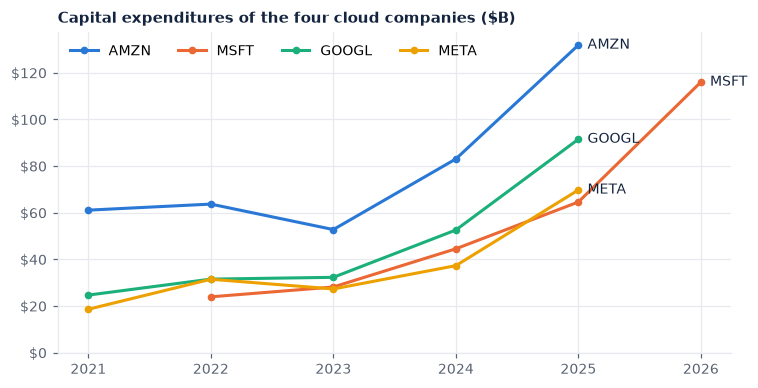

In [17]:
cloud = annual[annual["company"].isin(["AMZN", "MSFT", "GOOGL", "META"])]
capex = (
    cloud.pivot(index="fiscal_year", columns="company", values="capital_expenditures")
    / 1e9
)

fig, ax = plt.subplots(figsize=(7, 3.6))
for color, company in zip(
    (BLUE, ORANGE, GREEN, YELLOW), ["AMZN", "MSFT", "GOOGL", "META"]
):
    series = capex[company].dropna()
    ax.plot(
        series.index,
        series.values,
        color=color,
        linewidth=2,
        marker="o",
        markersize=4,
        label=company,
    )
    ax.annotate(
        company,
        (series.index[-1], series.iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=TEXT,
    )
ax.set_title("Capital expenditures of the four cloud companies ($B)")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.legend(frameon=False, ncols=4, loc="upper left")
plt.tight_layout()
capex.round(1)

In [18]:
cloud_reinvestment = sql("""
    select coalesce(c.primary_ticker, c.company_name) as company,
           f.fiscal_year,
           round(f.capital_expenditures / 1e9, 1) as capex_bn,
           round(f.operating_cash_flow / 1e9, 1) as ocf_bn,
           round((f.capital_expenditures / f.operating_cash_flow) * 100, 1) as capex_of_ocf_pct
    from gold.fct_company_financials as f
    join gold.dim_companies as c using (cik)
    where f.fiscal_period = 'FY'
      and c.primary_ticker in ('AMZN', 'MSFT', 'GOOGL', 'META')
    order by company, f.fiscal_year
""")
cloud_reinvestment

,company,fiscal_year,capex_bn,ocf_bn,capex_of_ocf_pct
0,AMZN,2021,61.100,46.300,131.800
1,AMZN,2022,63.600,46.800,136.100
2,AMZN,2023,52.700,84.900,62.100
3,AMZN,2024,83.000,115.900,71.600
4,AMZN,2025,131.800,139.500,94.500
5,GOOGL,2021,24.600,91.700,26.900
6,GOOGL,2022,31.500,91.500,34.400
7,GOOGL,2023,32.300,101.700,31.700
8,GOOGL,2024,52.500,125.300,41.900
9,GOOGL,2025,91.400,164.700,55.500


Together, the cloud companies increased annual capex from $128.2B in their baseline years to $408.8B in their latest fiscal years (a 3.2× expansion), with almost the entirety of the surge occurring between FY2024 and FY2026. Amazon reinvested 94.5% of its entire operating cash flow ($131.8B of $139.5B) back into infrastructure, explaining why so little of Big Tech's headline net income translates into near-term distributable cash.

## 7. Seasonality vs. Secular Growth

We analyze quarterly revenue shares to determine whether cyclical intra-year peaks exist across the cohort.

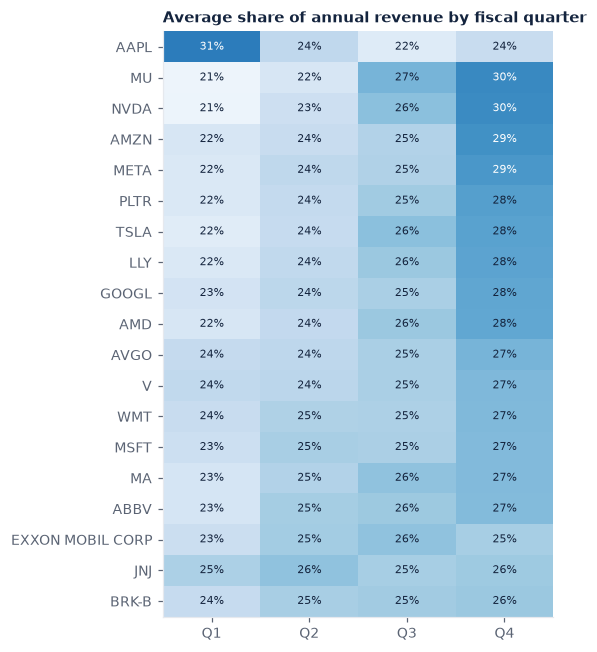

In [19]:
quarters = financials[
    financials["fiscal_period"].isin(["Q1", "Q2", "Q3", "Q4"])
].dropna(subset=["revenue"])
quarters = quarters.merge(
    annual[["company", "fiscal_year", "revenue"]],
    on=["company", "fiscal_year"],
    suffixes=("", "_annual"),
)
quarters["share"] = quarters["revenue"] / quarters["revenue_annual"]
share = quarters.pivot_table(
    index="company", columns="fiscal_period", values="share", aggfunc="mean"
)
share = share[share.notna().all(axis=1)]
share = share.loc[share.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(5.2, 6))
ax.imshow(share.values, cmap="Blues", vmin=0.2, vmax=0.35, aspect="auto")
ax.set_xticks(range(4), share.columns)
ax.set_yticks(range(len(share.index)), [name[:16] for name in share.index])
ax.grid(False)
for (row, column), value in pd.DataFrame(share.values).stack().items():
    ax.text(
        column,
        row,
        f"{value:.0%}",
        ha="center",
        va="center",
        fontsize=7,
        color="white" if value >= 0.29 else TEXT,
    )
ax.set_title("Average share of annual revenue by fiscal quarter")
plt.tight_layout()

Most companies report their largest revenue share in fiscal Q4, but for hyper-growth firms this reflects sequential intra-year expansion rather than recurring seasonal demand (e.g. NVIDIA and Micron both show ~30% in Q4 because each sequential quarter was significantly larger than the prior). In contrast, consumer-driven holiday seasonality is evident in Apple (Q1 peak at 31%, reflecting Oct-Dec), Amazon (Q4 peak at 29%), and Walmart (Q4 peak at 27%).

## 8. What this means for the dashboard

These findings decide how the **Insights** view is built:

1. **Ratios and margins over raw dollars:** Given the 160× revenue span, every comparative metric is standardized as a growth rate, margin percentage, or cash conversion ratio.
2. **Income & Cash Flow focus:** Due to structural omissions in consolidated liabilities (5 companies) and cash (2 companies), the analytics prioritizes income and cash flow statements where coverage is 99%+.
3. **Medians and compound metrics over means:** The heavy right-tail growth skew (NVIDIA, Micron) would distort arithmetic means; medians and CAGRs are used for robust cohort baselines.
4. **Keep outliers, explain them in writing:** Micron's pricing cycle, AbbVie's non-cash charges and J&J's Kenvue spin-off stay in the data. The dashboard only states what it computes, so context like this lives in the dated [written analysis](../docs/analysis/what-the-data-shows.md).
5. **The Capex finding:** The tripling of hyperscaler capex ($128B → $409B) explains the cash conversion compression, which is why it closes the Insights view.